# IBM Aachen: four-qubit logical H-state results

**B2_ED · no DD versus XY4 · October 14, 2026 (Pacific)**

This notebook displays the **two completed hardware experiments** and their saved
analysis. Each job used 24 circuits × 2,048 shots = **49,152 shots**. The state is
the encoded H-state of the [[4,1,2]] code. The acceptance rule is **recorded
syndrome `000`**, with no active error correction.

The headline comparison is raw fidelity **69.71% → 74.22%**, or **77.66% → 83.01%**
after correcting final data readout with the saved calibration. These are
measurement-based estimates, not exact density-matrix fidelities.

**Data-only execution:** all cells read existing files in `results/hardware_b2ed`.
They check hashes, recompute two estimates from the recorded counts, and render
tables and plots. No IBM service, simulator, new calibration, new bootstrap, or
hardware submission is invoked. Saved outputs make the notebook viewable on GitHub.

Use the **Python (quantum-jax)** kernel and **Run All**, from either the repository
root or the `notebooks` directory. No package installation is needed.

In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json
import os
import sys
import tempfile

cache = Path(tempfile.gettempdir()) / 'qompute-hardware-notebook-mpl'
cache.mkdir(exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(cache))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'results/hardware_b2ed/four_pilot_20261014/manifest.json').is_file())
DATA = ROOT / 'results/hardware_b2ed'
def read_json(path):
    return json.loads(path.read_text())
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()
def percent_ci(row, key='normal_95_interval'):
    lo, hi = row[key]
    return f'{100*lo:.2f}–{100*hi:.2f}%'
def show_table(rows):
    frame = pd.DataFrame(rows)
    display(frame.style.hide(axis='index'))
    return frame

plt.rcParams.update({'figure.dpi': 115, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold',
                     'axes.grid': False, 'savefig.facecolor': 'white'})
COLORS = {'No DD': '#3A6EA5', 'XY4': '#D06B32'}
RAW = 'raw_recorded_zero'
CORRECTED = 'data_corrected_recorded_zero'
JOINT = 'joint_corrected_true_zero'

mitigation = read_json(DATA / 'readout_mitigation_20261014/readout_mitigation.json')
runs = {}
for label, folder in [('No DD', 'four_pilot_20261014'), ('XY4', 'four_xy4_20261014')]:
    directory = DATA / folder
    runs[label] = {'directory': directory,
                   'manifest': read_json(directory / 'manifest.json'),
                   'receipt': read_json(directory / 'submission.json'),
                   'analysis': read_json(directory / 'analysis_extended.json'),
                   'counts': read_json(directory / 'joint_counts.json'),
                   'calibration': read_json(directory / 'calibration.json'),
                   'replay': read_json(directory / 'calibration_replay.json')}
    runs[label]['mitigation'] = next(r for r in mitigation['runs']
                                    if r['job_id'] == runs[label]['receipt']['job_id'])
comparison = read_json(runs['XY4']['directory'] / 'xy4_vs_no_dd.json')
print(f'Python {sys.version.split()[0]} | NumPy {np.__version__} | pandas {pd.__version__}')
print('Source: archived hardware counts and completed analysis files only.')

Python 3.11.14 | NumPy 1.26.4 | pandas 2.3.3
Source: archived hardware counts and completed analysis files only.


## 1. Which experiments are being compared?

The routing patch is `[3, 2, 4, 16, 1, 5, 23, 0, 6]`. The final physical data
qubits, in data-bit order, are `[5, 3, 2, 16]`; syndrome bits 0, 1, 2 are measured
on `[1, 4, 23]` and correspond to `XXXX`, `IIZZ`, `ZZII`.

The XY4 run adds native X/Y/X/Y pulses in eligible idle windows. The existing
gates, mapping and preparation duration are unchanged. These were **sequential
jobs about 24.5 minutes apart**, not an interleaved randomized comparison.

In [2]:
provenance_rows = []
for label, run in runs.items():
    m, receipt = run['manifest'], run['receipt']
    res = m['resources']
    local_time = datetime.fromisoformat(receipt['submitted_at_utc']).astimezone(ZoneInfo('America/Los_Angeles'))
    provenance_rows.append({'Run': label, 'IBM job ID': receipt['job_id'],
                            'Submitted (Pacific)': local_time.strftime('%Y-%m-%d %H:%M:%S'),
                            'Circuits': m['number_of_circuits'], 'Shots': m['total_shots'],
                            'Prep duration (µs)': f"{1e6*res['duration_seconds']:.3f}",
                            'CZ gates': res['two_qubit_gates'],
                            'Added DD X pulses': res.get('dd', {}).get('added_native_x_pulses', 0)})
provenance_table = show_table(provenance_rows)
print('Backend: ibm_aachen | instance: qzh-eu')
print(f"Submission separation: {comparison['submission_gap_minutes']:.2f} minutes")
print('Identical saved calibration:', comparison['identical_saved_calibration'])

Run,IBM job ID,Submitted (Pacific),Circuits,Shots,Prep duration (µs),CZ gates,Added DD X pulses
No DD,db84dj8331ic73fu5jfg,2026-10-14 20:21:50,24,49152,5.020,39,0
XY4,db84p30331ic73fu5tm0,2026-10-14 20:46:20,24,49152,5.020,39,36


Backend: ibm_aachen | instance: qzh-eu
Submission separation: 24.50 minutes
Identical saved calibration: True


## 2. Fidelity of the actually accepted ensemble

Both columns below retain the **same recorded-`000` shots**. The corrected column
inverts only final **data** assignment errors, using the saved per-qubit
calibration. It does not change acceptance or repair the prepared state.

Error bars are **approximate 95% sampling intervals**. They omit calibration
uncertainty, hardware drift, correlated readout and analysis-basis errors. The
saved 10,000-replicate bootstrap provides a separate finite-shot cross-check.

Run,Raw fidelity,Raw 95% interval,Data-corrected fidelity,Corrected 95% interval,Corrected bootstrap 95%
No DD,69.71%,68.49–70.92%,77.66%,76.26–79.05%,76.26–79.01%
XY4,74.22%,73.06–75.38%,83.01%,81.68–84.34%,81.68–84.35%


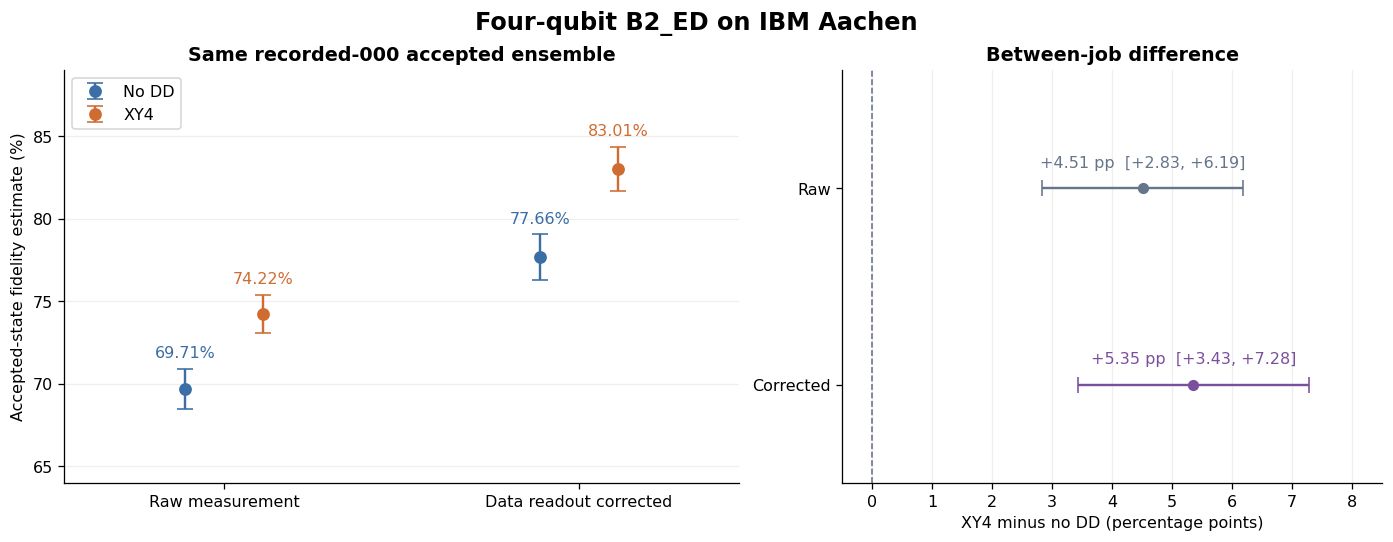

In [3]:
fidelity_rows = []
for label, run in runs.items():
    r = run['mitigation']['fidelity']
    fidelity_rows.append({'Run': label, 'Raw fidelity': f"{r[RAW]['estimate']:.2%}",
                          'Raw 95% interval': percent_ci(r[RAW]),
                          'Data-corrected fidelity': f"{r[CORRECTED]['estimate']:.2%}",
                          'Corrected 95% interval': percent_ci(r[CORRECTED]),
                          'Corrected bootstrap 95%': percent_ci(r[CORRECTED], 'bootstrap_95_interval')})
fidelity_table = show_table(fidelity_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained',
                         gridspec_kw={'width_ratios': [1.25, 1]})
positions = np.arange(2)
for label, offset in [('No DD', -.11), ('XY4', .11)]:
    values = [runs[label]['mitigation']['fidelity'][mode] for mode in [RAW, CORRECTED]]
    y = 100*np.array([r['estimate'] for r in values])
    bounds = 100*np.array([r['normal_95_interval'] for r in values])
    axes[0].errorbar(positions+offset, y, yerr=np.array([y-bounds[:, 0], bounds[:, 1]-y]),
                     fmt='o', markersize=7, capsize=5, color=COLORS[label], label=label)
    for x, value, upper in zip(positions+offset, y, bounds[:, 1]):
        axes[0].annotate(f'{value:.2f}%', (x, upper), xytext=(0, 7),
                         textcoords='offset points', ha='center', color=COLORS[label])
axes[0].set(xticks=positions, xticklabels=['Raw measurement', 'Data readout corrected'],
            ylabel='Accepted-state fidelity estimate (%)', ylim=(64, 89), xlim=(-.45, 1.45),
            title='Same recorded-000 accepted ensemble')
axes[0].legend(loc='upper left')
axes[0].grid(axis='y', alpha=.2)
for y, mode, color in [(1, RAW, '#65758B'), (0, CORRECTED, '#7A4F9D')]:
    r = mitigation['comparison'][mode]
    point = 100*r['estimate']
    lo, hi = 100*np.array(r['normal_95_interval'])
    axes[1].errorbar(point, y, xerr=[[point-lo], [hi-point]], fmt='o', color=color, capsize=5)
    axes[1].annotate(f'+{point:.2f} pp  [{lo:+.2f}, {hi:+.2f}]', (point, y),
                     xytext=(0, 13), textcoords='offset points', ha='center', color=color)
axes[1].axvline(0, color='#667085', ls='--', lw=1)
axes[1].set(yticks=[0, 1], yticklabels=['Corrected', 'Raw'], ylim=(-.5, 1.6), xlim=(-.5, 8.5),
            xlabel='XY4 minus no DD (percentage points)', title='Between-job difference')
axes[1].grid(axis='x', alpha=.2)
fig.suptitle('Four-qubit B2_ED on IBM Aachen', fontsize=15, weight='bold')
plt.show()

The data-corrected difference is **+5.35 percentage points**, with a sampling
interval of **[+3.43, +7.28] points**. The higher XY4 score is consistent with a
benefit from decoupling, while the sequential-job design leaves drift unresolved.
Readout mitigation increases the fidelity estimates and also increases their
sampling standard errors by about 15%; it does not make the underlying quantum
states better.

## 3. Acceptance and recorded syndrome outcomes

The dedicated acceptance-only circuit provides the primary acceptance estimate.
Pooled acceptance uses all 24 settings and is supplementary. Data-readout
mitigation leaves both unchanged.

Syndrome strings are displayed as **`s2 s1 s0`**. A nonzero recorded syndrome
causes rejection; it does not uniquely identify a hardware fault.

Run,Dedicated accepted / attempts,Dedicated acceptance,Wilson 95%,Pooled accepted / attempts,Pooled acceptance
No DD,"992 / 2,048",48.44%,46.28–50.60%,"24,022 / 49,152",48.87%
XY4,"1,044 / 2,048",50.98%,48.81–53.14%,"24,596 / 49,152",50.04%


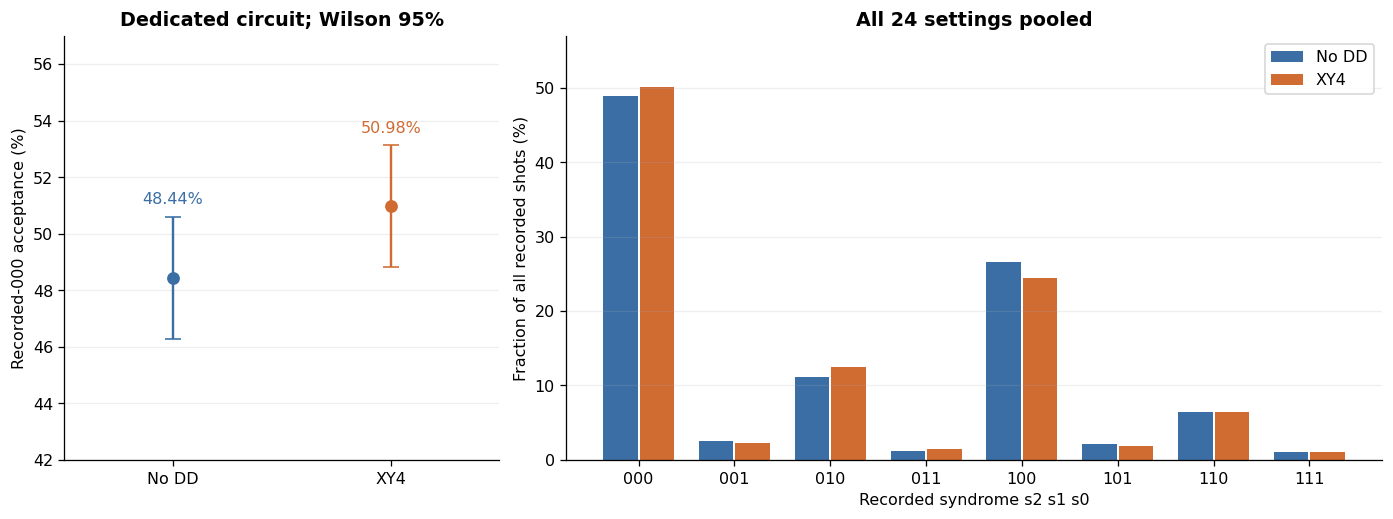

Dedicated acceptance difference: **+2.54 points**, 95% sampling interval **[-0.52, +5.60] points**. This interval includes zero.

In [4]:
acceptance_rows = []
for label, run in runs.items():
    a, pooled = run['analysis']['primary_acceptance'], run['analysis']['pooled_acceptance']
    acceptance_rows.append({'Run': label,
                            'Dedicated accepted / attempts': f"{a['accepted_shots']:,} / {a['shots']:,}",
                            'Dedicated acceptance': f"{a['acceptance']:.2%}",
                            'Wilson 95%': percent_ci(a, 'acceptance_wilson_95_interval'),
                            'Pooled accepted / attempts': f"{pooled['accepted']:,} / {pooled['attempted']:,}",
                            'Pooled acceptance': f"{pooled['estimate']:.2%}"})
acceptance_table = show_table(acceptance_rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout='constrained',
                         gridspec_kw={'width_ratios': [.8, 1.5]})
for i, (label, run) in enumerate(runs.items()):
    a = run['analysis']['primary_acceptance']
    value = 100*a['acceptance']
    low, high = 100*np.array(a['acceptance_wilson_95_interval'])
    axes[0].errorbar(i, value, yerr=[[value-low], [high-value]], fmt='o', capsize=5,
                     color=COLORS[label], markersize=7)
    axes[0].annotate(f'{value:.2f}%', (i, high), xytext=(0, 8),
                     textcoords='offset points', ha='center', color=COLORS[label])
axes[0].set(xticks=[0, 1], xticklabels=list(runs), xlim=(-.5, 1.5), ylim=(42, 57),
            ylabel='Recorded-000 acceptance (%)', title='Dedicated circuit; Wilson 95%')
axes[0].grid(axis='y', alpha=.2)
syndromes = [format(i, '03b') for i in range(8)]
x = np.arange(8)
for label, offset in [('No DD', -.19), ('XY4', .19)]:
    a = runs[label]['analysis']
    proportions = [100*a['syndrome_counts'].get(s, 0)/a['total_shots'] for s in syndromes]
    axes[1].bar(x+offset, proportions, width=.36, label=label, color=COLORS[label])
axes[1].set(xticks=x, xticklabels=syndromes, xlabel='Recorded syndrome s2 s1 s0',
            ylabel='Fraction of all recorded shots (%)', ylim=(0, 57), title='All 24 settings pooled')
axes[1].legend()
axes[1].grid(axis='y', alpha=.2)
plt.show()

d = comparison['metrics']['primary_acceptance']
display(Markdown(f"Dedicated acceptance difference: **{100*d['difference']:+.2f} points**, "
                 f"95% sampling interval **[{100*d['normal_95_interval'][0]:+.2f}, "
                 f"{100*d['normal_95_interval'][1]:+.2f}] points**. This interval includes zero."))

## 4. What readout correction does—and which ensemble it describes

For each qubit the saved assignment matrix is

$$A_q[\text{true},\text{recorded}]
=\begin{pmatrix}1-e_{01}&e_{01}\\ e_{10}&1-e_{10}\end{pmatrix}.$$

Corrected parity weights solve $A_q w_q=(1,-1)^T$. Multiplying the relevant
single-qubit weights corrects each measured Pauli parity. The original target
projector coefficients are retained.

**Primary result:** invert data readout, while keeping selection on **recorded
`000`**. **Additional diagnostic:** invert syndrome assignment as well and
estimate a distribution conditioned on **latent true `000`**. The latter changes
the selected ensemble; it does not identify or recover individual misread shots.

The calibration was measured around 19:34 Pacific, about 48 and 72 minutes before
the two jobs. It assumes independent assignment errors. There were no dedicated
calibration circuits in these jobs, and calibration uncertainty is unavailable.

In [5]:
calibration_rows = []
for role in ['data', 'syndrome']:
    for row in runs['No DD']['mitigation']['calibration'][role]:
        calibration_rows.append({'Role': role, 'Classical bit': row['bit'],
                                 'Physical qubit': row['physical_qubit'],
                                 'P(record 1 | true 0)': f"{row['p_record_1_given_0']:.3%}",
                                 'P(record 0 | true 1)': f"{row['p_record_0_given_1']:.3%}"})
calibration_table = show_table(calibration_rows)
diagnostic_rows = []
for label, run in runs.items():
    r = run['mitigation']
    diagnostic_rows.append({'Run': label,
                            'Recorded-000 fidelity, data corrected': f"{r['fidelity'][CORRECTED]['estimate']:.2%}",
                            'Latent-000 fidelity, joint corrected': f"{r['fidelity'][JOINT]['estimate']:.2%}",
                            'Recorded-000 acceptance': f"{r['dedicated_acceptance']['recorded_zero']['estimate']:.2%}",
                            'Estimated latent-000 probability': f"{r['dedicated_acceptance']['true_zero_diagnostic']['estimate']:.2%}"})
diagnostic_table = show_table(diagnostic_rows)

Role,Classical bit,Physical qubit,P(record 1 | true 0),P(record 0 | true 1)
data,0,5,0.244%,0.439%
data,1,3,0.732%,1.416%
data,2,2,2.344%,4.443%
data,3,16,3.125%,2.490%
syndrome,0,1,0.098%,0.781%
syndrome,1,4,0.684%,1.270%
syndrome,2,23,0.342%,1.025%


Run,"Recorded-000 fidelity, data corrected","Latent-000 fidelity, joint corrected",Recorded-000 acceptance,Estimated latent-000 probability
No DD,77.66%,77.94%,48.44%,48.54%
XY4,83.01%,83.32%,50.98%,51.15%


### Sensitivity to the saved calibration

The following values were already computed in the saved analysis. Multiplying
all directional readout-error rates by a common factor illustrates sensitivity
to calibration strength. **These factors are scenarios, not a confidence interval
for the calibration.** A larger corrected number alone does not validate a model.

In [6]:
sensitivity_rows = []
for b, a in zip(runs['No DD']['mitigation']['assignment_rate_sensitivity'],
                 runs['XY4']['mitigation']['assignment_rate_sensitivity']):
    x, y = b['fidelity'][CORRECTED], a['fidelity'][CORRECTED]
    sensitivity_rows.append({'Assignment-error multiplier': b['rate_multiplier'],
                             'No DD corrected fidelity': f'{x:.2%}',
                             'XY4 corrected fidelity': f'{y:.2%}',
                             'XY4 minus no DD (points)': f'{100*(y-x):+.2f}'})
sensitivity_table = show_table(sensitivity_rows)

Assignment-error multiplier,No DD corrected fidelity,XY4 corrected fidelity,XY4 minus no DD (points)
0.000000,69.71%,74.22%,+4.51
0.500000,73.49%,78.40%,+4.91
1.000000,77.66%,83.01%,+5.35
1.500000,82.27%,88.12%,+5.85


## 5. Code-subspace score

The seven measured nonidentity stabilizer-group terms also estimate the
code-subspace projector. This is a **measurement-derived score**, not an exact
density-matrix decomposition. It remains affected by basis-gate and calibration
errors. No extra codespace filtering is performed, and no exact within-codespace
fidelity is inferred by dividing these estimates.

In [7]:
codespace_rows = []
for label, run in runs.items():
    r = run['mitigation']['codespace_score']
    codespace_rows.append({'Run': label, 'Raw code-subspace score': f"{r[RAW]['estimate']:.2%}",
                          'Data-corrected score': f"{r[CORRECTED]['estimate']:.2%}",
                          'Corrected 95% sampling interval': percent_ci(r[CORRECTED])})
codespace_table = show_table(codespace_rows)

Run,Raw code-subspace score,Data-corrected score,Corrected 95% sampling interval
No DD,71.06%,79.02%,77.26–80.77%
XY4,76.03%,84.86%,83.24–86.47%


## 6. Reconstruct the fidelity from the archived counts

This is a deterministic check of the existing data, not a new experiment. For
each of the 23 Pauli settings, select recorded `000` and evaluate raw and
data-corrected parity. Recombine the saved target-projector coefficients:

$$\widehat F=c_I+\sum_{P\ne I}c_P\widehat{\langle P\rangle}_{\mathrm{recorded}\;000}.$$

Qiskit bit strings are little-endian: the three rightmost bits are the syndrome,
and data bit 0 is the rightmost data bit. Statistical variance is summed over
independently measured Pauli settings. The calculations below do not use Qiskit,
Aer, IBM Runtime, or any random resampling.

In [8]:
reconstruction_rows = []
pauli_rows = []
for label, run in runs.items():
    m, calibration = run['manifest'], run['calibration']
    matrices = []
    for physical in m['resources']['final_data_physical_qubits']:
        properties = {v['name']: v['value'] for v in calibration['qubits'][physical]}
        e01, e10 = properties['prob_meas1_prep0'], properties['prob_meas0_prep1']
        matrices.append(np.array([[1-e01, e01], [e10, 1-e10]]))
    fidelities = np.full(2, m['identity_coefficient'])
    variances = np.zeros(2)
    for setting, counts in zip(m['settings'][1:], run['counts'][1:]):
        selected = np.zeros(16)
        for bits, n in counts.items():
            value = int(bits, 2)
            if value & 7 == 0:
                selected[value >> 3] += n
        n = selected.sum()
        assert n > 1
        weights = np.ones((16, 2))
        for bit, p in enumerate(reversed(setting['pauli'])):
            if p != 'I':
                index = (np.arange(16) >> bit) & 1
                weights[:, 0] *= np.array([1., -1.])[index]
                weights[:, 1] *= np.linalg.solve(matrices[bit], [1., -1.])[index]
        means = selected @ weights/n
        variance = np.maximum(0, selected @ (weights**2)/n-means**2)/(n-1)
        fidelities += setting['coefficient']*means
        variances += setting['coefficient']**2*variance
        pauli_rows.append({'Run': label, 'Pauli': setting['pauli'],
                           'Coefficient': setting['coefficient'], 'Accepted shots': int(n),
                           'Raw expectation': means[0], 'Data-corrected expectation': means[1]})
    for i, mode in enumerate([RAW, CORRECTED]):
        reference = run['mitigation']['fidelity'][mode]
        np.testing.assert_allclose(fidelities[i], reference['estimate'], atol=1e-12, rtol=0)
        np.testing.assert_allclose(np.sqrt(variances[i]), reference['standard_error'], atol=1e-12, rtol=0)
        reconstruction_rows.append({'Run': label, 'Estimator': ['Raw', 'Data corrected'][i],
                                    'Count reconstruction': f'{fidelities[i]:.10f}',
                                    'Saved estimate': f"{reference['estimate']:.10f}",
                                    'Absolute difference': f"{abs(fidelities[i]-reference['estimate']):.2e}",
                                    'Standard error': f'{np.sqrt(variances[i]):.6f}'})
reconstruction_table = show_table(reconstruction_rows)
pauli_table = pd.DataFrame(pauli_rows)
print('PASS: both fidelity estimates and their standard errors match for both jobs.')

Run,Estimator,Count reconstruction,Saved estimate,Absolute difference,Standard error
No DD,Raw,0.6970853078,0.6970853078,0.00e+00,0.006195
No DD,Data corrected,0.7765876198,0.7765876198,0.00e+00,0.007117
XY4,Raw,0.7421923975,0.7421923975,0.00e+00,0.005899
XY4,Data corrected,0.8301105184,0.8301105184,0.00e+00,0.006773


PASS: both fidelity estimates and their standard errors match for both jobs.


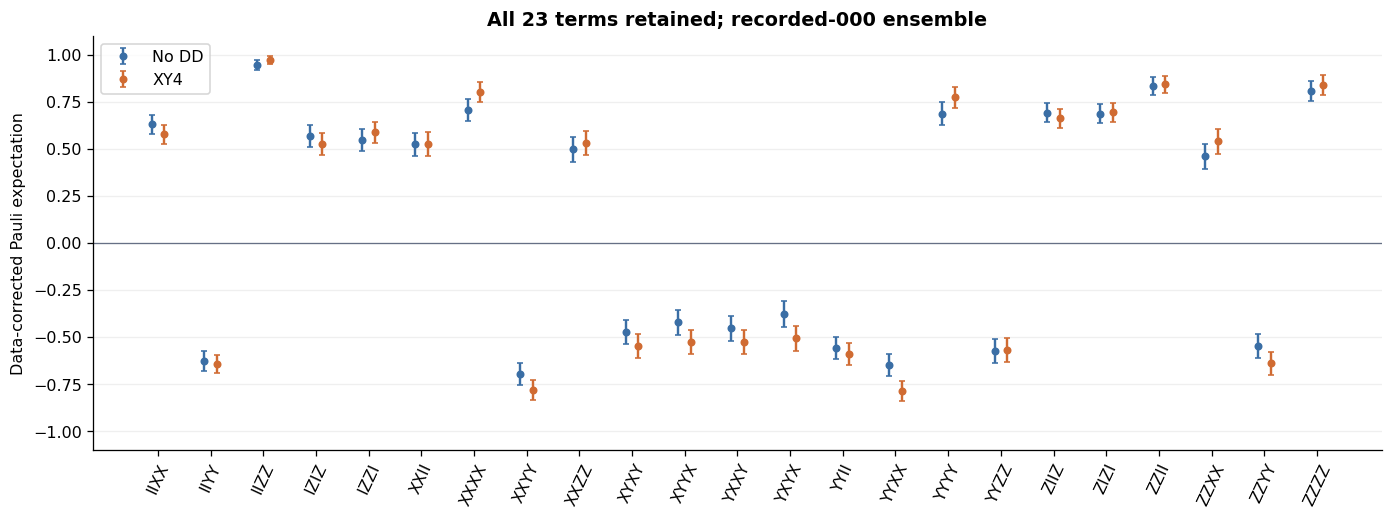

Error bars are pointwise 95% normal intervals; terms are not individually selected for significance.

In [9]:
fig, ax = plt.subplots(figsize=(12, 4.4), layout='constrained')
paulis = [setting['pauli'] for setting in runs['No DD']['manifest']['settings'][1:]]
x = np.arange(len(paulis))
for label, offset in [('No DD', -.12), ('XY4', .12)]:
    saved = runs[label]['mitigation']['per_pauli']
    y = [term['expectations'][CORRECTED] for term in saved]
    err = [1.95996398454*term['standard_errors'][CORRECTED] for term in saved]
    ax.errorbar(x+offset, y, yerr=err, fmt='o', markersize=4, capsize=2,
                color=COLORS[label], label=label)
ax.axhline(0, color='#667085', lw=.8)
ax.set(xticks=x, xticklabels=paulis, ylim=(-1.1, 1.1),
        ylabel='Data-corrected Pauli expectation',
        title='All 23 terms retained; recorded-000 ensemble')
ax.tick_params(axis='x', rotation=65)
ax.grid(axis='y', alpha=.2)
ax.legend()
plt.show()
display(Markdown('Error bars are pointwise 95% normal intervals; terms are not individually selected for significance.'))

## 7. Previously saved noise-model replay

The following simulation results were already saved before this notebook was
created. **No simulation is run here.** Compare the hardware raw measurement
score with the simulated raw measurement score. The model's exact delivered-state
fidelity is a separate quantity and is available only inside the simulation.

This independent Markovian model predicts a slight decrease with XY4, unlike the
observed hardware difference. It omits slow coherent/correlated noise that DD may
suppress, crosstalk, drift, unreported controller latency and other device effects.
It also substantially overestimates acceptance, so it is not a validated model
of the full hardware process.

In [10]:
model_rows = []
for label, run in runs.items():
    model, hardware = run['replay'], run['analysis']
    model_rows.append({'Run': label,
                       'Hardware acceptance': f"{hardware['primary_acceptance']['acceptance']:.2%}",
                       'Model acceptance': f"{model['acceptance']:.2%}",
                       'Hardware raw score': f"{hardware['groups']['accepted']['raw_fidelity']:.2%}",
                       'Model raw score': f"{model['raw_measurement_score']:.2%}",
                       'Exact model fidelity (simulation only)': f"{model['exact_model_preparation_fidelity']:.2%}"})
model_table = show_table(model_rows)

Run,Hardware acceptance,Model acceptance,Hardware raw score,Model raw score,Exact model fidelity (simulation only)
No DD,48.44%,91.44%,69.71%,84.28%,94.60%
XY4,50.98%,91.17%,74.22%,83.98%,94.27%


## 8. Archive integrity and interpretation limits

The check below verifies the submitted manifest, all manifest-bound files, and
the raw inputs bound to the saved mitigation analysis. Counts must contain all
24 requested settings with 2,048 shots each. Readout calibration and acquisition
settings must match across the jobs. SHA256 checks establish consistency with
the archived records, not independent authentication of the device.

Interpretation remains limited by finite shots, saved-calibration applicability,
analysis-gate bias and the sequential-run design. Syndrome postselection does not
prove fault tolerance or imply that an accepted output stays in the code space.

In [11]:
validation_rows = []
for label, run in runs.items():
    directory, m = run['directory'], run['manifest']
    assert sha256(directory / 'manifest.json') == run['receipt']['manifest_sha256']
    expected = {**m['files'], **run['mitigation']['input_sha256']}
    for name, digest in expected.items():
        assert sha256(directory / name) == digest, f'{label}: hash mismatch for {name}'
    assert len(run['counts']) == m['number_of_circuits'] == 24
    for setting, counts in zip(m['settings'], run['counts']):
        width = 3 if setting['kind'] == 'acceptance' else 7
        assert all(len(bits) == width and set(bits) <= {'0', '1'} for bits in counts)
        assert sum(counts.values()) == m['shots_per_circuit'] == 2048
    assert sum(sum(c.values()) for c in run['counts']) == m['total_shots'] == 49152
    validation_rows.append({'Run': label, 'Hashed files verified': len(expected),
                            'Shots verified': m['total_shots'],
                            'Manifest SHA256 (prefix)': sha256(directory/'manifest.json')[:16],
                            'Status': 'PASS'})
base, xy4 = runs['No DD']['manifest'], runs['XY4']['manifest']
for field in ['settings', 'shots_per_circuit', 'stabilizers_in_syndrome_bit_order']:
    assert base[field] == xy4[field]
for field in ['duration_seconds', 'final_data_physical_qubits', 'syndrome_physical_qubits_in_bit_order']:
    assert base['resources'][field] == xy4['resources'][field]
assert base['files']['calibration.json'] == xy4['files']['calibration.json']
assert sha256(ROOT/'scripts/mitigate_ibm_b2ed_readout.py') == mitigation['script_sha256']
validation_table = show_table(validation_rows)
print('PASS: archive hashes, shot budgets, protocol matching, and count-based reconstructions.')
print('Execution used archived data only. No IBM API or simulator was imported or called.')

Run,Hashed files verified,Shots verified,Manifest SHA256 (prefix),Status
No DD,10,49152,1e707e27a488b3cc,PASS
XY4,10,49152,025ff88c6d932f45,PASS


PASS: archive hashes, shot budgets, protocol matching, and count-based reconstructions.
Execution used archived data only. No IBM API or simulator was imported or called.


## Saved reports and source files

- [Raw hardware comparison](../results/hardware_b2ed/four_xy4_20261014/xy4_vs_no_dd.md)
- [Readout mitigation and calibration sensitivity](../results/hardware_b2ed/readout_mitigation_20261014/readout_mitigation.md)
- [Hardware protocol and job-handling scripts](../docs/ibm_b2ed_pilot.md)
- [No-DD archived results](../results/hardware_b2ed/four_pilot_20261014/)
- [XY4 archived results](../results/hardware_b2ed/four_xy4_20261014/)
- [Mitigation implementation](../scripts/mitigate_ibm_b2ed_readout.py)

**Material Passport:** academic-research-suite / experiment-agent; mode: validate;
status: **ANALYZED** (archived hardware, deterministic postprocessing checked).
The saved mitigation report contains the full 11-item statistical interpretation
audit. The hardware experiments have not been repeated for this notebook.